In [ ]:
!pip install yfinance ta pandas --quiet


In [ ]:
import yfinance as yf
import pandas as pd
import ta
import zipfile
from google.colab import files
import os

# --- 1. Define assets and time range ---
assets = {
    "BTC-USD": "Bitcoin",
    "ETH-USD": "Ethereum",
    "^GSPC": "S&P500"
}

start_date = "2018-01-01"
end_date = "2023-12-31"

# --- 2. Create folder to store CSVs temporarily ---
os.makedirs("financial_data", exist_ok=True)

# --- 3. Function to download and process data ---
def fetch_and_process(symbol, name):
    # Download historical OHLCV data
    df = yf.download(symbol, start=start_date, end=end_date, auto_adjust=True)
    df.dropna(inplace=True)

    # Add technical indicators
    df['RSI'] = ta.momentum.RSIIndicator(df['Close'].squeeze(), window=14).rsi()

    macd = ta.trend.MACD(df['Close'].squeeze())
    df['MACD'] = macd.macd()
    df['MACD_Signal'] = macd.macd_signal()
    df['MACD_Hist'] = macd.macd_diff()

    df['EMA_12'] = ta.trend.EMAIndicator(df['Close'].squeeze(), window=12).ema_indicator()
    df['EMA_26'] = ta.trend.EMAIndicator(df['Close'].squeeze(), window=26).ema_indicator()

    # Save CSV
    filename = f"financial_data/{name}_data.csv"
    df.to_csv(filename)
    print(f"Saved {filename} with {len(df)} rows.")

# --- 4. Download data for all assets ---
for symbol, name in assets.items():
    fetch_and_process(symbol, name)

# --- 5. Create ZIP file ---
zip_filename = "financial_data.zip"
with zipfile.ZipFile(zip_filename, 'w') as zipf:
    for root, dirs, files_in_dir in os.walk("financial_data"):
        for file in files_in_dir:
            zipf.write(os.path.join(root, file), arcname=file)

print(f"Created {zip_filename} containing all CSVs")



[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed

Saved financial_data/Bitcoin_data.csv with 2190 rows.
Saved financial_data/Ethereum_data.csv with 2190 rows.


Saved financial_data/S&P500_data.csv with 1509 rows.
Created financial_data.zip containing all CSVs


In [ ]:
from google.colab import files
files.download("financial_data.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files
import zipfile
import os

# Upload the ZIP
uploaded = files.upload()  # Select financial_data.zip

# Extract ZIP
with zipfile.ZipFile("financial_data.zip", 'r') as zip_ref:
    zip_ref.extractall("financial_data")

# Check extracted files
os.listdir("financial_data")


Saving financial_data (3).zip to financial_data (3).zip


['Ethereum_data.csv', 'Bitcoin_data.csv', 'S&P500_data.csv']

In [ ]:
import os
os.listdir("financial_data")


['Ethereum_data.csv', 'Bitcoin_data.csv', 'S&P500_data.csv']

In [ ]:
assets = {
    "BTC": "financial_data/Bitcoin_data.csv",
    "ETH": "financial_data/Ethereum_data.csv",
    "SP500": "financial_data/S&P500_data.csv"
}


In [ ]:
import pandas as pd

df = pd.read_csv("financial_data/Bitcoin_data.csv")
print(df.columns)


Index(['Price', 'Close', 'High', 'Low', 'Open', 'Volume', 'RSI', 'MACD',
       'MACD_Signal', 'MACD_Hist', 'EMA_12', 'EMA_26'],
      dtype='object')


In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
import os

# --- 1. Set asset file paths ---
assets = {
    "BTC": "financial_data/Bitcoin_data.csv",
    "ETH": "financial_data/Ethereum_data.csv",
    "SP500": "financial_data/S&P500_data.csv"
}

# Features that are numeric in your CSVs
features = ['Open', 'High', 'Low', 'Close', 'Volume', 'RSI',
            'MACD', 'MACD_Signal', 'MACD_Hist', 'EMA_12', 'EMA_26']
lag_days = 10
output_dir = "preprocessed_data"
os.makedirs(output_dir, exist_ok=True)

# --- 2. Function to create lag sequences ---
def create_sequences(data, lag=10):
    X, y = [], []
    for i in range(lag, len(data)):
        X.append(data[i-lag:i])
        y.append(data[i, 3])  # predicting 'Close'
    return np.array(X), np.array(y)

# --- 3. Process each asset ---
for asset, file_path in assets.items():
    # Load CSV
    df = pd.read_csv(file_path)

    # Keep only numeric columns that exist in features
    numeric_cols = [col for col in features if col in df.columns]
    df = df[numeric_cols]

    # Convert to numeric in case there are strings
    df = df.apply(pd.to_numeric, errors='coerce')

    # Handle missing values
    df.ffill(inplace=True)
    df.bfill(inplace=True)

    # Normalize features
    scaler = MinMaxScaler()
    df_scaled = scaler.fit_transform(df)

    # Create lag sequences
    X, y = create_sequences(df_scaled, lag=lag_days)

    # Split dataset
    train_size = int(0.7 * len(X))
    val_size = int(0.15 * len(X))

    X_train, y_train = X[:train_size], y[:train_size]
    X_val, y_val = X[train_size:train_size+val_size], y[train_size:train_size+val_size]
    X_test, y_test = X[train_size+val_size:], y[train_size+val_size:]

    # Save as CSVs
    np.savetxt(f"{output_dir}/{asset}_X_train.csv", X_train.reshape(X_train.shape[0], -1), delimiter=",")
    np.savetxt(f"{output_dir}/{asset}_y_train.csv", y_train, delimiter=",")
    np.savetxt(f"{output_dir}/{asset}_X_val.csv", X_val.reshape(X_val.shape[0], -1), delimiter=",")
    np.savetxt(f"{output_dir}/{asset}_y_val.csv", y_val, delimiter=",")
    np.savetxt(f"{output_dir}/{asset}_X_test.csv", X_test.reshape(X_test.shape[0], -1), delimiter=",")
    np.savetxt(f"{output_dir}/{asset}_y_test.csv", y_test, delimiter=",")

    print(f"{asset}: Preprocessing complete. Train/Val/Test CSVs saved in {output_dir}")


BTC: Preprocessing complete. Train/Val/Test CSVs saved in preprocessed_data
ETH: Preprocessing complete. Train/Val/Test CSVs saved in preprocessed_data
SP500: Preprocessing complete. Train/Val/Test CSVs saved in preprocessed_data


In [ ]:
import shutil
from google.colab import files

# Zip the preprocessed_data folder
shutil.make_archive("preprocessed_data", 'zip', "preprocessed_data")

# Download the zip file
files.download("preprocessed_data.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import shutil
from google.colab import files

shutil.make_archive("preprocessed_data", 'zip', "preprocessed_data")
files.download("preprocessed_data.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files
import zipfile

# Upload the zip file from your computer
uploaded = files.upload()

# Extract it
with zipfile.ZipFile("preprocessed_data.zip", 'r') as zip_ref:
    zip_ref.extractall("preprocessed_data")

print(" Preprocessed data extracted to 'preprocessed_data/'")


Saving preprocessed_data (8).zip to preprocessed_data (8).zip
 Preprocessed data extracted to 'preprocessed_data/'


In [ ]:
from google.colab import files
import zipfile

# Upload the zip file you downloaded earlier
uploaded = files.upload()   # choose "preprocessed_data.zip" from your PC

# Extract it so the training script can see the CSVs
with zipfile.ZipFile("preprocessed_data.zip", 'r') as zip_ref:
    zip_ref.extractall("preprocessed_data")

print(" Preprocessed data ready in 'preprocessed_data/'")


Saving preprocessed_data (8).zip to preprocessed_data (8) (1).zip
 Preprocessed data ready in 'preprocessed_data/'


In [ ]:
!ls preprocessed_data


BTC_X_test.csv	 BTC_y_val.csv	  ETH_y_train.csv    SP500_y_test.csv
BTC_X_train.csv  ETH_X_test.csv   ETH_y_val.csv      SP500_y_train.csv
BTC_X_val.csv	 ETH_X_train.csv  SP500_X_test.csv   SP500_y_val.csv
BTC_y_test.csv	 ETH_X_val.csv	  SP500_X_train.csv
BTC_y_train.csv  ETH_y_test.csv   SP500_X_val.csv


In [ ]:
# STEP 3: Helper function to prepare data
def load_and_prepare(paths):
    # Load feature and label files separately
    X_train = pd.read_csv(paths["X_train"]).values
    y_train = pd.read_csv(paths["y_train"]).values
    X_val   = pd.read_csv(paths["X_val"]).values
    y_val   = pd.read_csv(paths["y_val"]).values
    X_test  = pd.read_csv(paths["X_test"]).values
    y_test  = pd.read_csv(paths["y_test"]).values

    # Reshape for LSTM [samples, timesteps, features]
    X_train = X_train.reshape((X_train.shape[0], 1, X_train.shape[1]))
    X_val   = X_val.reshape((X_val.shape[0], 1, X_val.shape[1]))
    X_test  = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))

    return X_train, y_train, X_val, y_val, X_test, y_test


# STEP 5: Train and evaluate
def train_asset(asset_name, paths):
    print(f"\n🚀 Training LSTM for {asset_name}...\n")
    X_train, y_train, X_val, y_val, X_test, y_test = load_and_prepare(paths)

    model = build_model((X_train.shape[1], X_train.shape[2]))
    early_stop = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=30,
        batch_size=32,
        callbacks=[early_stop],
        verbose=1
    )

    # Evaluate
    y_pred = model.predict(X_test)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)

    print(f"{asset_name} - Test RMSE: {rmse:.4f}, Test MAE: {mae:.4f}")

    # Save model
    model_path = f"models/{asset_name}_LSTM.h5"
    model.save(model_path)
    print(f" Saved model: {model_path}")

    # Plot predictions
    plt.figure(figsize=(10,5))
    plt.plot(y_test[:200], label="Actual")
    plt.plot(y_pred[:200], label="Predicted")
    plt.title(f"{asset_name} - LSTM Prediction vs Actual")
    plt.legend()
    plot_path = f"plots/{asset_name}_LSTM_plot.png"
    plt.savefig(plot_path)
    plt.show()
    print(f" Saved plot: {plot_path}\n")


# STEP 6: Loop over all assets
for asset, paths in assets.items():
    train_asset(asset, paths)

    train_asset(asset, paths)



🚀 Training LSTM for BTC...



TypeError: string indices must be integers, not 'str'

In [ ]:
!ls
!ls preprocessed_data


 financial_data		     'preprocessed_data (5).zip'
'financial_data (1).zip'     'preprocessed_data (6).zip'
'financial_data (2).zip'     'preprocessed_data (7).zip'
'financial_data (3).zip'     'preprocessed_data (8) (1).zip'
 financial_data.zip	     'preprocessed_data (8).zip'
 GRU_plots.zip		      preprocessed_data.zip
 models			      sample_data
 plots			      shap_plots
 plots.zip		      shap_results
 preprocessed_data	      Transformer_plots.zip
'preprocessed_data (4).zip'
BTC_X_test.csv	 BTC_y_val.csv	  ETH_y_train.csv    SP500_y_test.csv
BTC_X_train.csv  ETH_X_test.csv   ETH_y_val.csv      SP500_y_train.csv
BTC_X_val.csv	 ETH_X_train.csv  SP500_X_test.csv   SP500_y_val.csv
BTC_y_test.csv	 ETH_X_val.csv	  SP500_X_train.csv
BTC_y_train.csv  ETH_y_test.csv   SP500_X_val.csv


In [ ]:
from google.colab import files
import glob

# Download all plots
for plot in glob.glob("plots/*.png"):
    files.download(plot)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


🚀 Training LSTM for BTC...



/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


LookupError: gradient registry has no entry for: shap_DivNoNan

In [ ]:
# ================================
# Combined LSTM / GRU / Transformer
# Regression + Classification Metrics
# ================================

import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error, precision_score, recall_score, f1_score
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import LSTM, GRU, Dense, Dropout, Input, MultiHeadAttention, LayerNormalization
from tensorflow.keras.callbacks import EarlyStopping

# -------------------------------
# Asset file paths
# -------------------------------
assets = {
    "BTC": {
        "X_train": "preprocessed_data/BTC_X_train.csv",
        "y_train": "preprocessed_data/BTC_y_train.csv",
        "X_val":   "preprocessed_data/BTC_X_val.csv",
        "y_val":   "preprocessed_data/BTC_y_val.csv",
        "X_test":  "preprocessed_data/BTC_X_test.csv",
        "y_test":  "preprocessed_data/BTC_y_test.csv",
    },
    "ETH": {
        "X_train": "preprocessed_data/ETH_X_train.csv",
        "y_train": "preprocessed_data/ETH_y_train.csv",
        "X_val":   "preprocessed_data/ETH_X_val.csv",
        "y_val":   "preprocessed_data/ETH_y_val.csv",
        "X_test":  "preprocessed_data/ETH_X_test.csv",
        "y_test":  "preprocessed_data/ETH_y_test.csv",
    },
    "S&P500": {
        "X_train": "preprocessed_data/SP500_X_train.csv",
        "y_train": "preprocessed_data/SP500_y_train.csv",
        "X_val":   "preprocessed_data/SP500_X_val.csv",
        "y_val":   "preprocessed_data/SP500_y_val.csv",
        "X_test":  "preprocessed_data/SP500_X_test.csv",
        "y_test":  "preprocessed_data/SP500_y_test.csv",
    }
}

os.makedirs("models", exist_ok=True)
os.makedirs("plots", exist_ok=True)

# -------------------------------
# Load & prepare data
# -------------------------------
def load_and_prepare(paths):
    X_train = pd.read_csv(paths["X_train"]).values
    y_train = pd.read_csv(paths["y_train"]).values.flatten()
    X_val   = pd.read_csv(paths["X_val"]).values
    y_val   = pd.read_csv(paths["y_val"]).values.flatten()
    X_test  = pd.read_csv(paths["X_test"]).values
    y_test  = pd.read_csv(paths["y_test"]).values.flatten()

    # Reshape [samples, timesteps=1, features]
    X_train = X_train.reshape((X_train.shape[0], 1, X_train.shape[1]))
    X_val   = X_val.reshape((X_val.shape[0], 1, X_val.shape[1]))
    X_test  = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))

    return X_train, y_train, X_val, y_val, X_test, y_test

# -------------------------------
# Models
# -------------------------------
def build_lstm(input_shape):
    model = Sequential([
        LSTM(64, return_sequences=False, input_shape=input_shape),
        Dropout(0.2),
        Dense(32, activation="relu"),
        Dense(1)
    ])
    model.compile(optimizer="adam", loss="mse", metrics=["mae"])
    return model

def build_gru(input_shape):
    model = Sequential([
        GRU(64, return_sequences=False, input_shape=input_shape),
        Dropout(0.2),
        Dense(32, activation="relu"),
        Dense(1)
    ])
    model.compile(optimizer="adam", loss="mse", metrics=["mae"])
    return model

def build_transformer(input_shape, num_heads=4, ff_dim=64):
    inputs = Input(shape=input_shape)
    x = MultiHeadAttention(num_heads=num_heads, key_dim=input_shape[1])(inputs, inputs)
    x = LayerNormalization(epsilon=1e-6)(x)
    x = Dense(ff_dim, activation="relu")(x)
    x = Dense(1)(x)
    model = Model(inputs, x)
    model.compile(optimizer="adam", loss="mse", metrics=["mae"])
    return model

# -------------------------------
# Training & Evaluation
# -------------------------------
def evaluate_classification(y_true, y_pred):
    # Convert regression outputs into UP/DOWN (binary)
    y_true_class = (np.diff(np.concatenate([[y_true[0]], y_true])) > 0).astype(int)
    y_pred_class = (np.diff(np.concatenate([[y_pred[0]], y_pred])) > 0).astype(int)

    precision = precision_score(y_true_class, y_pred_class, zero_division=0)
    recall = recall_score(y_true_class, y_pred_class, zero_division=0)
    f1 = f1_score(y_true_class, y_pred_class, zero_division=0)

    return precision, recall, f1

models_builders = {
    "LSTM": build_lstm,
    "GRU": build_gru,
    "Transformer": build_transformer
}

results = []

for model_name, builder in models_builders.items():
    for asset, paths in assets.items():
        print(f"\n🚀 Training {model_name} for {asset}...\n")
        X_train, y_train, X_val, y_val, X_test, y_test = load_and_prepare(paths)

        model = builder((X_train.shape[1], X_train.shape[2]))
        early_stop = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

        model.fit(
            X_train, y_train,
            validation_data=(X_val, y_val),
            epochs=30,
            batch_size=32,
            callbacks=[early_stop],
            verbose=0
        )

        # Predictions
        y_pred = model.predict(X_test).flatten()

        # Regression metrics
        rmse = np.sqrt(mean_squared_error(y_test, y_pred))
        mae = mean_absolute_error(y_test, y_pred)
        mape = np.mean(np.abs((y_test - y_pred) / y_test)) * 100

        # Classification metrics
        precision, recall, f1 = evaluate_classification(y_test, y_pred)

        results.append([asset, model_name, rmse, mae, mape, precision, recall, f1])

        # Save model
        model.save(f"models/{asset}_{model_name}.h5")

        # Plot predictions
        plt.figure(figsize=(10,5))
        plt.plot(y_test[:200], label="Actual")
        plt.plot(y_pred[:200], label="Predicted")
        plt.title(f"{asset} - {model_name} Prediction vs Actual")
        plt.legend()
        plt.savefig(f"plots/{asset}_{model_name}_plot.png")
        plt.close()

# -------------------------------
# Save Final Results
# -------------------------------
df_results = pd.DataFrame(results, columns=["Asset", "Model", "RMSE", "MAE", "MAPE (%)", "Precision", "Recall", "F1"])
df_results.to_csv("models/final_results.csv", index=False)
print("\n📊 Final Combined Results:")
print(df_results)



🚀 Training LSTM for BTC...



/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


LookupError: gradient registry has no entry for: shap_DivNoNan

In [ ]:
from google.colab import files
files.download("models/LSTM_results.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import shutil
shutil.make_archive("plots", 'zip', "plots")
files.download("plots.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# =========================
# GRU TRAINING SCRIPT
# =========================

import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GRU, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Asset file paths
assets = {
    "BTC": {
        "X_train": "preprocessed_data/BTC_X_train.csv",
        "y_train": "preprocessed_data/BTC_y_train.csv",
        "X_val":   "preprocessed_data/BTC_X_val.csv",
        "y_val":   "preprocessed_data/BTC_y_val.csv",
        "X_test":  "preprocessed_data/BTC_X_test.csv",
        "y_test":  "preprocessed_data/BTC_y_test.csv",
    },
    "ETH": {
        "X_train": "preprocessed_data/ETH_X_train.csv",
        "y_train": "preprocessed_data/ETH_y_train.csv",
        "X_val":   "preprocessed_data/ETH_X_val.csv",
        "y_val":   "preprocessed_data/ETH_y_val.csv",
        "X_test":  "preprocessed_data/ETH_X_test.csv",
        "y_test":  "preprocessed_data/ETH_y_test.csv",
    },
    "S&P500": {
        "X_train": "preprocessed_data/SP500_X_train.csv",
        "y_train": "preprocessed_data/SP500_y_train.csv",
        "X_val":   "preprocessed_data/SP500_X_val.csv",
        "y_val":   "preprocessed_data/SP500_y_val.csv",
        "X_test":  "preprocessed_data/SP500_X_test.csv",
        "y_test":  "preprocessed_data/SP500_y_test.csv",
    }
}

os.makedirs("models", exist_ok=True)
os.makedirs("plots", exist_ok=True)

# Load and prepare function
def load_and_prepare(paths):
    X_train = pd.read_csv(paths["X_train"]).values
    y_train = pd.read_csv(paths["y_train"]).values.flatten()
    X_val   = pd.read_csv(paths["X_val"]).values
    y_val   = pd.read_csv(paths["y_val"]).values.flatten()
    X_test  = pd.read_csv(paths["X_test"]).values
    y_test  = pd.read_csv(paths["y_test"]).values.flatten()

    # Reshape for GRU [samples, timesteps, features]
    X_train = X_train.reshape((X_train.shape[0], 1, X_train.shape[1]))
    X_val   = X_val.reshape((X_val.shape[0], 1, X_val.shape[1]))
    X_test  = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))

    return X_train, y_train, X_val, y_val, X_test, y_test

# Build GRU model
def build_gru(input_shape):
    model = Sequential([
        GRU(64, return_sequences=False, input_shape=input_shape),
        Dropout(0.2),
        Dense(32, activation="relu"),
        Dense(1)
    ])
    model.compile(optimizer="adam", loss="mse", metrics=["mae"])
    return model

# Train and evaluate
results = []
for asset, paths in assets.items():
    print(f"\n🚀 Training GRU for {asset}...\n")
    X_train, y_train, X_val, y_val, X_test, y_test = load_and_prepare(paths)

    model = build_gru((X_train.shape[1], X_train.shape[2]))
    early_stop = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=30,
        batch_size=32,
        callbacks=[early_stop],
        verbose=1
    )

    # Evaluate
    y_pred = model.predict(X_test)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    mape = np.mean(np.abs((y_test - y_pred) / y_test)) * 100

    print(f"{asset} - Test RMSE: {rmse:.4f}, Test MAE: {mae:.4f}, Test MAPE: {mape:.2f}%")

    results.append([asset, "GRU", rmse, mae, mape])

    # Save model
    model_path = f"models/{asset}_GRU.h5"
    model.save(model_path)

    # Plot predictions
    plt.figure(figsize=(10,5))
    plt.plot(y_test[:200], label="Actual")
    plt.plot(y_pred[:200], label="Predicted")
    plt.title(f"{asset} - GRU Prediction vs Actual")
    plt.legend()
    plt.savefig(f"plots/{asset}_GRU_plot.png")
    plt.show()

# Save results table
df_results = pd.DataFrame(results, columns=["Asset", "Model", "RMSE", "MAE", "MAPE (%)"])
df_results.to_csv("models/GRU_results.csv", index=False)
print("\n GRU Results saved to models/GRU_results.csv")
print(df_results)



🚀 Training GRU for BTC...

Epoch 1/30


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


LookupError: gradient registry has no entry for: shap_DivNoNan

In [ ]:
from google.colab import files

# Download the GRU results table
files.download("models/GRU_results.csv")



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import shutil

# Zip the GRU plots folder (assuming saved in "plots/")
shutil.make_archive("GRU_plots", 'zip', "plots")

# Download the zip
files.download("GRU_plots.zip")



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# STEP 1: Imports
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense, Dropout, LayerNormalization, MultiHeadAttention

# STEP 2: Assets
assets = {
    "BTC": {
        "X_train": "preprocessed_data/BTC_X_train.csv",
        "y_train": "preprocessed_data/BTC_y_train.csv",
        "X_val":   "preprocessed_data/BTC_X_val.csv",
        "y_val":   "preprocessed_data/BTC_y_val.csv",
        "X_test":  "preprocessed_data/BTC_X_test.csv",
        "y_test":  "preprocessed_data/BTC_y_test.csv",
    },
    "ETH": {
        "X_train": "preprocessed_data/ETH_X_train.csv",
        "y_train": "preprocessed_data/ETH_y_train.csv",
        "X_val":   "preprocessed_data/ETH_X_val.csv",
        "y_val":   "preprocessed_data/ETH_y_val.csv",
        "X_test":  "preprocessed_data/ETH_X_test.csv",
        "y_test":  "preprocessed_data/ETH_y_test.csv",
    },
    "S&P500": {
        "X_train": "preprocessed_data/SP500_X_train.csv",
        "y_train": "preprocessed_data/SP500_y_train.csv",
        "X_val":   "preprocessed_data/SP500_X_val.csv",
        "y_val":   "preprocessed_data/SP500_y_val.csv",
        "X_test":  "preprocessed_data/SP500_X_test.csv",
        "y_test":  "preprocessed_data/SP500_y_test.csv",
    }
}

os.makedirs("models", exist_ok=True)
os.makedirs("plots", exist_ok=True)

# STEP 3: Load data
def load_and_prepare(x_path, y_path, x_val_path, y_val_path, x_test_path, y_test_path):
    X_train = pd.read_csv(x_path).values
    y_train = pd.read_csv(y_path).values.flatten()
    X_val   = pd.read_csv(x_val_path).values
    y_val   = pd.read_csv(y_val_path).values.flatten()
    X_test  = pd.read_csv(x_test_path).values
    y_test  = pd.read_csv(y_test_path).values.flatten()

    # Reshape: [samples, timesteps=1, features]
    X_train = X_train.reshape((X_train.shape[0], 1, X_train.shape[1]))
    X_val   = X_val.reshape((X_val.shape[0], 1, X_val.shape[1]))
    X_test  = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))

    return X_train, y_train, X_val, y_val, X_test, y_test

# STEP 4: Transformer block
def transformer_encoder(inputs, head_size, num_heads, ff_dim, dropout=0):
    x = MultiHeadAttention(num_heads=num_heads, key_dim=head_size)(inputs, inputs)
    x = Dropout(dropout)(x)
    x = LayerNormalization(epsilon=1e-6)(x)
    res = x + inputs

    x = Dense(ff_dim, activation="relu")(res)
    x = Dropout(dropout)(x)
    x = Dense(inputs.shape[-1])(x)
    x = LayerNormalization(epsilon=1e-6)(x)
    return x + res

# STEP 5: Build Transformer model
from tensorflow.keras.layers import GlobalAveragePooling1D

def build_transformer(input_shape):
    inputs = Input(shape=input_shape)
    x = transformer_encoder(inputs, head_size=32, num_heads=2, ff_dim=64, dropout=0.2)
    x = GlobalAveragePooling1D()(x)   # ✅ replaces tf.reduce_mean
    x = Dense(32, activation="relu")(x)
    outputs = Dense(1)(x)
    model = Model(inputs, outputs)
    model.compile(optimizer="adam", loss="mse", metrics=["mae"])
    return model


# STEP 6: Train & evaluate
results = []

for asset, paths in assets.items():
    print(f"\n🚀 Training Transformer for {asset}...\n")
    X_train, y_train, X_val, y_val, X_test, y_test = load_and_prepare(
        paths["X_train"], paths["y_train"],
        paths["X_val"], paths["y_val"],
        paths["X_test"], paths["y_test"]
    )

    model = build_transformer((X_train.shape[1], X_train.shape[2]))

    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=30,
        batch_size=32,
        verbose=1
    )

    # Evaluate
    y_pred = model.predict(X_test).flatten()
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    mape = np.mean(np.abs((y_test - y_pred) / y_test)) * 100

    results.append([asset, "Transformer", rmse, mae, mape])
    print(f"{asset} - RMSE: {rmse:.4f}, MAE: {mae:.4f}, MAPE: {mape:.2f}%")

    # Save plot
    plt.figure(figsize=(10,5))
    plt.plot(y_test[:200], label="Actual")
    plt.plot(y_pred[:200], label="Predicted")
    plt.title(f"{asset} - Transformer Prediction vs Actual")
    plt.legend()
    plot_path = f"plots/{asset}_Transformer_plot.png"
    plt.savefig(plot_path)
    plt.close()
    print(f"Saved plot: {plot_path}")

# STEP 7: Save results
results_df = pd.DataFrame(results, columns=["Asset", "Model", "RMSE", "MAE", "MAPE (%)"])
results_df.to_csv("models/Transformer_results.csv", index=False)
print("\n Transformer Results saved to models/Transformer_results.csv")
print(results_df)



🚀 Training Transformer for BTC...

Epoch 1/30


LookupError: gradient registry has no entry for: shap_DivNoNan

In [ ]:
from google.colab import files
files.download("models/Transformer_results.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import shutil
from google.colab import files

# Zip only Transformer plots
shutil.make_archive("Transformer_plots", 'zip', "plots")

# Download zip
files.download("Transformer_plots.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd
from google.colab import files

# Load individual results
lstm_df = pd.read_csv("models/LSTM_results.csv")
gru_df = pd.read_csv("models/GRU_results.csv")
transformer_df = pd.read_csv("models/Transformer_results.csv")

# Merge into one master table
all_results = pd.concat([lstm_df, gru_df, transformer_df], ignore_index=True)

# Save master results
all_results.to_csv("models/All_Models_results.csv", index=False)

print(" Combined results saved to models/All_Models_results.csv")
display(all_results)

# Download the final results
files.download("models/All_Models_results.csv")


 Combined results saved to models/All_Models_results.csv


,Asset,Model,RMSE,MAE,MAPE (%)
0,BTC,LSTM,0.013023,0.009685,21.554346
1,ETH,LSTM,0.014581,0.011541,13.233749
2,S&P500,LSTM,0.030285,0.024983,11.285298
3,BTC,GRU,0.014175,0.011176,21.222516
4,ETH,GRU,0.016051,0.012535,13.448318
5,S&P500,GRU,0.042324,0.036912,11.759111
6,BTC,Transformer,0.035726,0.032838,8.451780
7,ETH,Transformer,0.017187,0.014962,4.146650
8,S&P500,Transformer,0.022196,0.017399,2.139453


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# STEP 1: Imports
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras.models import load_model
import os

# STEP 2: Choose ONE asset at a time
asset = "BTC"   # change to "ETH" or "S&P500"
model_path = f"models/{asset}_LSTM.h5"
data_path = f"preprocessed_data/{asset}_X_test.csv"

# STEP 3: Load model and data
model = load_model(model_path)
X_test = pd.read_csv(data_path)
feature_names = X_test.columns

X_test_np = np.array(X_test)
X_test_np = X_test_np.reshape((X_test_np.shape[0], 1, X_test_np.shape[1]))

# STEP 4: Make output folders
os.makedirs("shap_plots", exist_ok=True)
os.makedirs("shap_results", exist_ok=True)

# STEP 5: Run SHAP with a SMALL sample
background = X_test_np[:50]   # background for DeepExplainer
explainer = shap.DeepExplainer(model, background)
shap_values = explainer.shap_values(X_test_np[:100])  # explain only 100 samples

# STEP 6: Convert to feature importance
mean_abs_shap = np.mean(np.abs(shap_values[0]), axis=0)
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "MeanAbsSHAP": mean_abs_shap,
    "Asset": asset
})

# Save feature importance
csv_path = f"shap_results/{asset}_LSTM_SHAP.csv"
feature_importance.to_csv(csv_path, index=False)
print(f"📊 Saved SHAP importance table: {csv_path}")

# STEP 7: Plot SHAP beeswarm
plt.title(f"{asset} - LSTM SHAP Feature Importance")
shap.summary_plot(
    shap_values[0],
    X_test_np[:100].reshape(100, -1),
    feature_names=feature_names,
    show=False
)
plot_path = f"shap_plots/{asset}_LSTM_SHAP.png"
plt.savefig(plot_path, bbox_inches="tight")
plt.close()
print(f"✅ Saved SHAP plot: {plot_path}")


TypeError: Could not locate function 'mse'. Make sure custom classes are decorated with `@keras.saving.register_keras_serializable()`. Full object config: {'module': 'keras.metrics', 'class_name': 'function', 'config': 'mse', 'registered_name': 'mse'}

In [ ]:
X_test = pd.read_csv(data_path, header=0)  # if headers exist
if not all(isinstance(c, str) for c in X_test.columns):
    X_test.columns = [f"F{i+1}" for i in range(X_test.shape[1])]


In [ ]:
X_test = pd.read_csv(data_path, header=0)  # if headers exist
if not all(isinstance(c, str) for c in X_test.columns):
    X_test.columns = [f"F{i+1}" for i in range(X_test.shape[1])]


In [ ]:
# STEP 1: Imports
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras.models import load_model
import os

# STEP 2: Assets
assets = {
    "BTC": "models/BTC_LSTM.h5",
    "ETH": "models/ETH_LSTM.h5",
    "SP500": "models/SP500_LSTM.h5"   # ✅ correct filename
}


# Ensure output dirs exist
os.makedirs("shap_results", exist_ok=True)
os.makedirs("shap_plots", exist_ok=True)

# To store results for consolidation
all_importances = {}

# STEP 3: SHAP runner
def run_shap_for_asset(asset, model_type="LSTM"):
    print(f"\n🔎 Running SHAP for {asset}_{model_type}...")

    # Paths
    model_path = f"models/{asset}_{model_type}.h5"
    data_path  = f"preprocessed_data/{asset}_X_test.csv"

    # --- Load model
    try:
        model = load_model(model_path, compile=False)
    except Exception as e:
        print(f"❌ Skipping {asset}_{model_type}, model load failed: {e}")
        return None

    # --- Load data
    try:
        X_test = pd.read_csv(data_path)

        # Fix feature names if numeric
        if not all(isinstance(c, str) for c in X_test.columns):
          feature_names = [f"F{i+1}" for i in range(X_test.shape[1])]


        feature_names = X_test.columns
        X_test_np = np.array(X_test)
        X_test_flat = X_test_np
        print(f"✅ Loaded {asset} test data → {X_test_flat.shape}")
    except Exception as e:
        print(f"❌ Skipping {asset}_{model_type}, data load failed: {e}")
        return None

    # Wrapper for correct input shape
    def model_predict_wrapped(x):
        return model.predict(x.reshape((x.shape[0], 1, x.shape[1])))

    # --- Run SHAP
    try:
        explainer = shap.KernelExplainer(model_predict_wrapped, X_test_flat[:20])
        shap_values = explainer.shap_values(X_test_flat[:50], nsamples=50)

        if isinstance(shap_values, list):
            shap_array = np.array(shap_values[0])
        else:
            shap_array = np.array(shap_values)

        print(f"📐 SHAP raw output shape → {shap_array.shape}")

        # Fix shape
        shap_array = np.squeeze(shap_array)
        mean_abs_shap = np.mean(np.abs(shap_array), axis=0)

        # Build DataFrame
        feature_importance = pd.DataFrame({
            "Feature": feature_names,
            f"{asset}_MeanAbsSHAP": mean_abs_shap.flatten()
        }).sort_values(f"{asset}_MeanAbsSHAP", ascending=False)

        # Save CSV
        out_csv = f"shap_results/{asset}_{model_type}_SHAP.csv"
        feature_importance.to_csv(out_csv, index=False)

        # Plot
        plt.figure(figsize=(8, 6))
        shap.summary_plot(
            shap_array,
            X_test_flat[:50],
            feature_names=feature_names,
            show=False
        )
        out_png = f"shap_plots/{asset}_{model_type}_SHAP.png"
        plt.savefig(out_png, bbox_inches="tight")
        plt.close()

        print(f"\n📊 {asset}_{model_type} Top 10 Features:")
        print(feature_importance.head(10).to_string(index=False))
        print(f"✅ CSV saved: {out_csv}")
        print(f"✅ Plot saved: {out_png}")

        return feature_importance

    except Exception as e:
        print(f"❌ SHAP failed for {asset}_{model_type}: {e}")
        return None

# STEP 4: Run all + consolidate
dfs = []
for asset in assets:
    df = run_shap_for_asset(asset, model_type)
    if df is not None:
        dfs.append(df)

# Merge all results by Feature
if dfs:
    consolidated = dfs[0]
    for df in dfs[1:]:
        consolidated = pd.merge(consolidated, df, on="Feature", how="outer")

    # Save consolidated CSV
    consolidated_out = "shap_results/All_LSTM_SHAP.csv"
    consolidated.to_csv(consolidated_out, index=False)
    print(f"\n✅ Consolidated SHAP saved: {consolidated_out}")
    print(consolidated.head(15).to_string(index=False))



🔎 Running SHAP for BTC_LSTM...
✅ Loaded BTC test data → (327, 110)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 201ms/step


  0%|          | 0/50 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 205ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_least_angle.py:723: ConvergenceWarning: Regressors in active set degenerate. Dropping a regressor, after 7 iterations, i.e. alpha=3.072e-04, with an active set of 7 regressors, and the smallest cholesky pivot element being 9.424e-08. Reduce max_iter or increase eps parameters.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_least_angle.py:723: ConvergenceWarning: Regressors in active set degenerate. Dropping a regressor, after 8 iterations, i.e. alpha=2.142e-04, with an active set of 8 regressors, and the smallest cholesky pivot element being 5.960e-08. Reduce max_iter or increase eps parameters.
  warnings.warn(


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step


...

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_least_angle.py:723: ConvergenceWarning: Regressors in active set degenerate. Dropping a regressor, after 2 iterations, i.e. alpha=1.748e-03, with an active set of 2 regressors, and the smallest cholesky pivot element being 5.960e-08. Reduce max_iter or increase eps parameters.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_least_angle.py:723: ConvergenceWarning: Regressors in active set degenerate. Dropping a regressor, after 6 iterations, i.e. alpha=1.245e-03, with an active set of 5 regressors, and the smallest cholesky pivot element being 7.300e-08. Reduce max_iter or increase eps parameters.
  warnings.warn(


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
📐 SHAP raw output shape → (50, 110, 1)


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_least_angle.py:723: ConvergenceWarning: Regressors in active set degenerate. Dropping a regressor, after 7 iterations, i.e. alpha=1.896e-03, with an active set of 7 regressors, and the smallest cholesky pivot element being 7.300e-08. Reduce max_iter or increase eps parameters.
  warnings.warn(



📊 SP500_LSTM Top 10 Features:
                 Feature  SP500_MeanAbsSHAP
5.799513647801373128e-01           0.002795
8.261093198271921567e-01           0.001329
7.529129982447155811e-01           0.001307
8.576538677473592998e-01           0.001181
6.217784304158096020e-01           0.001001
7.321465095513206567e-01           0.000948
5.637597077939000556e-01           0.000925
6.730846254522399041e-01           0.000841
7.460063073813523182e-01           0.000815
6.974510881932967088e-01           0.000801
✅ CSV saved: shap_results/SP500_LSTM_SHAP.csv
✅ Plot saved: shap_plots/SP500_LSTM_SHAP.png

✅ Consolidated SHAP saved: shap_results/All_LSTM_SHAP.csv
                 Feature  BTC_MeanAbsSHAP  ETH_MeanAbsSHAP  SP500_MeanAbsSHAP
1.150375200974736306e-01              NaN          0.00017                NaN
2.900326684410582945e-01         0.000276              NaN                NaN
2.930590193220282691e-01         0.000082              NaN                NaN
2.967970534641524161e-0

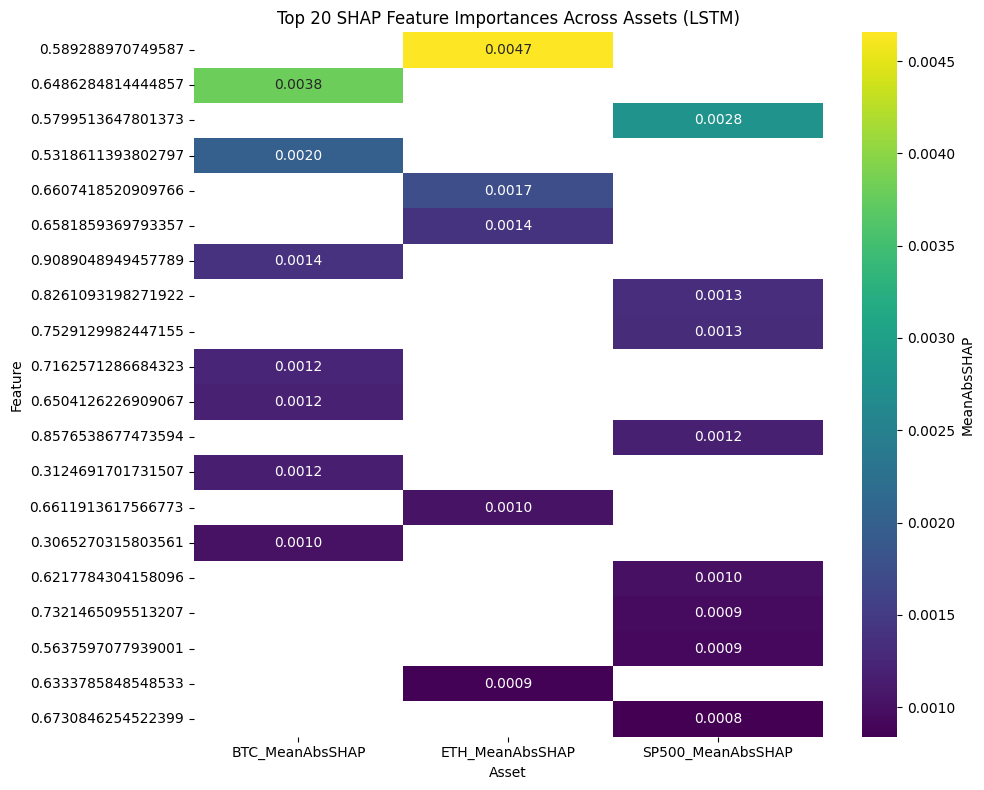

✅ Heatmap saved: shap_plots/All_LSTM_SHAP_Heatmap.png


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load consolidated SHAP results
all_shap = pd.read_csv("shap_results/All_LSTM_SHAP.csv")

# Drop rows where all assets are NaN
all_shap = all_shap.dropna(how="all", subset=["BTC_MeanAbsSHAP", "ETH_MeanAbsSHAP", "SP500_MeanAbsSHAP"])

# Keep top N features by average importance
top_n = 20
all_shap["MeanAcross"] = all_shap[["BTC_MeanAbsSHAP", "ETH_MeanAbsSHAP", "SP500_MeanAbsSHAP"]].mean(axis=1, skipna=True)
top_features = all_shap.nlargest(top_n, "MeanAcross")

# Reshape for heatmap
heatmap_data = top_features.set_index("Feature")[["BTC_MeanAbsSHAP", "ETH_MeanAbsSHAP", "SP500_MeanAbsSHAP"]]

# Plot heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(heatmap_data, annot=True, fmt=".4f", cmap="viridis", cbar_kws={'label': 'MeanAbsSHAP'})
plt.title("Top 20 SHAP Feature Importances Across Assets (LSTM)")
plt.xlabel("Asset")
plt.ylabel("Feature")
plt.tight_layout()

# Save plot
plt.savefig("shap_plots/All_LSTM_SHAP_Heatmap.png", dpi=300)
plt.show()

print("✅ Heatmap saved: shap_plots/All_LSTM_SHAP_Heatmap.png")


